# The Grand Tour with simultaneous GP: from a raw light curve to a planet's posterior, without detrending

**Level:** intermediate · **Run time:** ~2 min (the download, the first compilation and the fit) · This notebook appears in the tutorials of [TLS](https://github.com/hippke/tls) and [pizzetti](https://github.com/hippke/pizzetti). Its companion, [the Grand Tour with wotan](12%20The%20Grand%20Tour%20-%20from%20download%20to%20posterior.ipynb), takes the classical route.

**Covers:** downloading a K2 light curve with [lightkurve](https://lightkurve.github.io/lightkurve/), finding the planet with [TLS](https://github.com/hippke/tls) 2.0 + GP in the light curve as it is (the stellar variability as a Gaussian process, integrated out inside the search), fitting it with [pizzetti](https://github.com/hippke/pizzetti) and a Gaussian process by importance sampling, and reading the posterior

The [Grand Tour with wotan](12%20The%20Grand%20Tour%20-%20from%20download%20to%20posterior.ipynb) removes the star's variability first (detrending), searches the flat light curve and fits the transits afterwards. Here no step removes the variability: the search and the fit both model the star as a Gaussian process (GP), together with the transit. There is no filter and no window to choose, and the error bars of the fit include the uncertainty of the trend under every transit.

We pretend not to know the planet: K2-33 b, a Neptune-sized planet of a star only 5 to 10 million years old ([David et al. 2016](https://doi.org/10.1038/nature18293)). The young, spotted star changes its brightness by up to 20 ppt per day; the transits are 2.5 ppt deep.

| step | tool | figure |
|---|---|---|
| 1. download the light curve | lightkurve | 1 |
| 2. remove bad cadences | numpy | |
| 3. search for transits, with the star as a GP | TLS 2.0 + GP | 2, 3, 4 |
| 4. cut windows around the transits | numpy | |
| 5. fit the transit and a GP together | pizzetti (importance sampling) | 5, 6 |
| 6. physical quantities | numpy | 7 |

You need (the GP search of TLS and the GP of pizzetti are new; until their next releases, install both from GitHub):

```bash
pip install "transitleastsquares @ git+https://github.com/hippke/tls" "pizzetti[fit] @ git+https://github.com/hippke/pizzetti" lightkurve corner matplotlib
```

In [1]:
import math
import warnings
warnings.filterwarnings("ignore", category=UserWarning)     # lightkurve warns about an optional package
warnings.filterwarnings("ignore", category=RuntimeWarning)  # overflows while the optimiser probes extreme geometries
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import corner
from scipy.ndimage import median_filter
from transitleastsquares import gp
import pizzetti

## Step 1: download the light curve

K2 campaign 4, one point every 30 minutes for about 80 days, from the EVEREST pipeline: it removes K2's pointing
systematics, but keeps the star's own variability. EVEREST gives no flux uncertainties; TLS estimates them from
the point-to-point scatter.

2601 cadences of EPIC 205117205


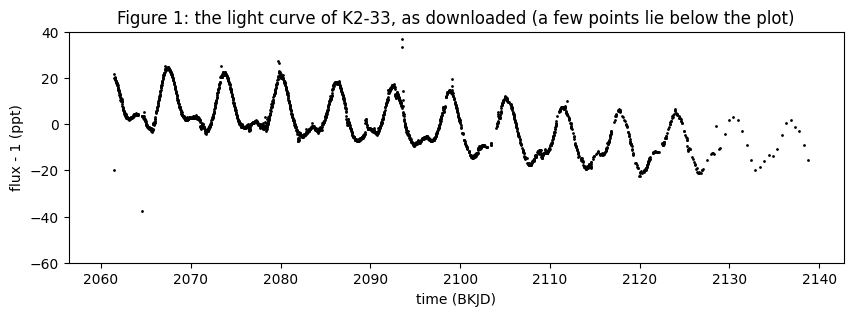

In [2]:
search = lk.search_lightcurve("K2-33", mission="K2", author="EVEREST", exptime=1800)
lc = search.download().remove_nans().normalize()
time = lc.time.value                       # days (BKJD = BJD - 2454833)
flux = np.asarray(lc.flux.value, dtype=float)
print(f"{len(time)} cadences of EPIC {lc.meta['KEPLERID']}")

plt.figure(figsize=(10, 3))
plt.plot(time, 1e3 * (flux - 1), "k.", ms=2)
plt.ylim(-60, 40)
plt.xlabel("time (BKJD)"); plt.ylabel("flux - 1 (ppt)")
plt.title("Figure 1: the light curve of K2-33, as downloaded (a few points lie below the plot)");

The star varies by tens of ppt; any transits are hidden in it. There are also bad cadences: a few dozen with a flux
near or below zero, and at the start of the campaign a short stretch about 90 ppt below the rest, before the
spacecraft has settled.

## Step 2: remove bad cadences

Every transit search takes the deepest dips seriously: left in, these cadences give a strong false signal at
32 days. We drop the cadences below 0.9, the first eight cadences, and single cadences far below both of their
neighbours. A transit lasts several cadences, so it is not touched. Nothing else is done to the light curve: no
detrending.

In [3]:
keep = flux > 0.9                                          # flux near or below zero: artefacts
keep &= time > time[keep][0] + 0.15                        # the first 8 cadences: about 90 ppt low
time, flux = time[keep], flux[keep]
d = np.diff(flux)
scatter = 1.4826 * np.median(np.abs(d - np.median(d))) / math.sqrt(2)   # white noise per point
single = np.zeros(len(flux), bool)
single[1:-1] = (flux[1:-1] < flux[:-2] - 6 * scatter) & (flux[1:-1] < flux[2:] - 6 * scatter)
time, flux = time[~single], flux[~single]
print(f"{len(time)} cadences kept, white noise {1e6 * scatter:.0f} ppm per point")

2526 cadences kept, white noise 336 ppm per point


## Step 3: search with TLS and a GP

`gp.search` takes the light curve as it is. It first fits a GP to the star (by default a rotation kernel: damped
oscillations at a rotation period and half of it, a slow trend and white noise), removing flares on the way. Then
it searches with the GP integrated out: every trial transit (period, duration, mid-transit time) is fitted
together with the GP, so the search sees the transit on top of the star's variability, not what a filter left of
it. The period grid is that of TLS.

The search needs the star's size and mass, which set the range of transit durations. The classical tour reads
them from the catalogue with `catalog_info`, but the K2 catalogue assumes main-sequence stars, and K2-33 is young
and still contracting. We take them from [David et al. (2016)](https://doi.org/10.1038/nature18293), R★ = 1.05 R☉
and M★ = 0.56 M☉, and allow a factor of 2 either way.

period 5.42358 d, SDE 33.6, depth 2382 ppm, duration 4.31 h, 14 transits; 43 flare points clipped


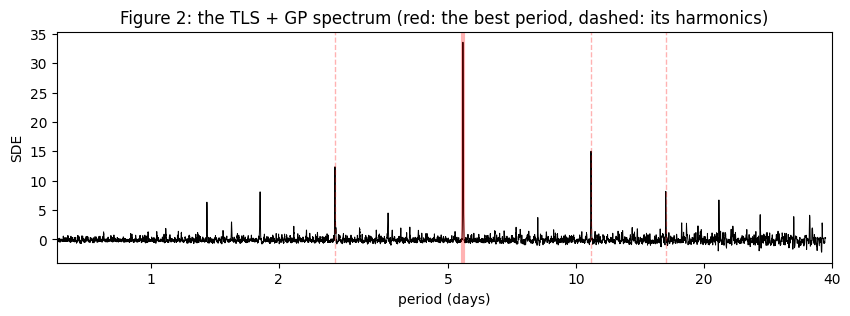

In [4]:
R_star, M_star = 1.05, 0.56                                # David et al. (2016)
found = gp.search(time, flux, R_star_min=R_star / 2, R_star_max=2 * R_star, M_star_min=M_star / 2, M_star_max=2 * M_star)
print(f"period {found.period:.5f} d, SDE {found.SDE:.1f}, depth {1e6 * found.depth:.0f} ppm, "
      f"duration {24 * found.duration:.2f} h, {len(found.transit_times)} transits; {(~found.use).sum()} flare points clipped")

plt.figure(figsize=(10, 3))
plt.plot(found.periods, found.power, "k", lw=0.7)
plt.axvline(found.period, color="r", alpha=0.3, lw=3)
for n in (2, 3, 0.5):
    plt.axvline(n * found.period, color="r", alpha=0.3, lw=1, ls="--")
plt.xscale("log"); plt.xlim(found.periods.min(), found.periods.max())
plt.xticks([1, 2, 5, 10, 20, 40], ["1", "2", "5", "10", "20", "40"]); plt.minorticks_off()
plt.xlabel("period (days)"); plt.ylabel("SDE")
plt.title("Figure 2: the TLS + GP spectrum (red: the best period, dashed: its harmonics)");

An SDE far above 9 is a clear detection, in a light curve whose variability is ten times deeper than the transit.
The result also holds the GP's trend: its posterior mean, conditioned on the data outside the transits. Dividing it
out shows the transits, although the search itself never used a detrended light curve:

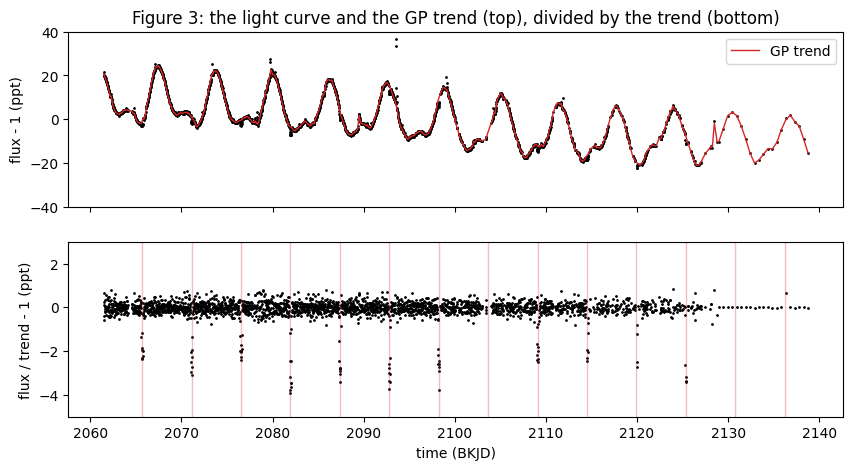

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(found.time, 1e3 * (found.flux - 1), "k.", ms=2)
ax[0].plot(found.time, 1e3 * (found.trend - 1), "C3", lw=1, label="GP trend")
ax[0].set_ylim(-40, 40); ax[0].set_ylabel("flux - 1 (ppt)"); ax[0].legend(loc="upper right")
ax[0].set_title("Figure 3: the light curve and the GP trend (top), divided by the trend (bottom)")
use = found.use
ax[1].plot(found.time[use], 1e3 * (found.flux[use] / found.trend[use] - 1), "k.", ms=2)
for tc in found.transit_times:
    ax[1].axvline(tc, color="C3", alpha=0.3, lw=1)
ax[1].set_ylim(-5, 3); ax[1].set_xlabel("time (BKJD)"); ax[1].set_ylabel("flux / trend - 1 (ppt)");

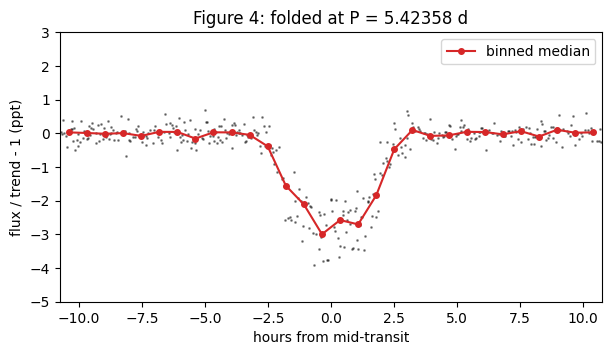

In [6]:
P, T0, T14 = found.period, found.T0, found.duration
ph = (found.time[use] - T0 + 0.5 * P) % P - 0.5 * P              # days from mid-transit
flat = found.flux[use] / found.trend[use]
bins = np.linspace(-2.5 * T14, 2.5 * T14, 31)
idx = np.digitize(ph, bins)
binned = [np.median(flat[idx == i]) for i in range(1, len(bins))]

plt.figure(figsize=(7, 3.5))
plt.plot(24 * ph, 1e3 * (flat - 1), "k.", ms=2, alpha=0.4)
plt.plot(24 * 0.5 * (bins[1:] + bins[:-1]), 1e3 * (np.array(binned) - 1), "C3o-", ms=4, label="binned median")
plt.xlim(-24 * 2.5 * T14, 24 * 2.5 * T14); plt.ylim(-5, 3); plt.legend()
plt.xlabel("hours from mid-transit"); plt.ylabel("flux / trend - 1 (ppt)")
plt.title(f"Figure 4: folded at P = {P:.5f} d");

## Step 4: windows around the transits, in time order

For the fit we keep ±3 durations around each transit: enough data outside the transit for the GP to learn the
trend there. Two things differ from the classical tour:

- **The light curve is not folded.** A GP correlates neighbours in time, so the windows stay in time order and the
  transits keep their own epochs.
- **Nothing is detrended.** The fit sees the raw flux, the trend and the transit together.

Outliers are removed per window, against a running median after dividing by a rough transit, and we keep the
windows with data on both sides of the transit. Times are counted from the first transit TLS found.

In [7]:
K = 15                                                     # sub-exposures for the 30-minute cadence
exposure = np.median(np.diff(time))                        # days

def start_params():
    """The transit that TLS found, as the start of the fit."""
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp = 0.0, P, math.sqrt(found.depth)
    p.a = P / (math.pi * T14)                               # a/R* of a central transit of this duration
    p.inc, p.ecc, p.w, p.limb_dark, p.u = 89.0, 0.0, 90.0, "quadratic", [0.4, 0.25]
    return p

phase = (time - T0 + 0.5 * P) % P - 0.5 * P
epoch = np.round((time - T0) / P).astype(int)
near = np.abs(phase) < 3 * T14
t, y, ep = time[near] - T0, flux[near], epoch[near]

p0 = start_params()
rough = pizzetti.TransitModel(p0, t, supersample_factor=K, exp_time=exposure, offsets="midpoint").light_curve(p0)
keep = np.ones(len(t), bool)
for e in np.unique(ep):
    m = ep == e
    r = y[m] / rough[m]
    keep[m] = np.abs(r - median_filter(r, size=5, mode="nearest")) < 5 * scatter
for e in np.unique(ep):                                    # data on both sides of the transit
    m = keep & (ep == e)
    h = t[m] - e * P
    if np.sum(h < -0.6 * T14) < 4 or np.sum(h > 0.6 * T14) < 4 or np.sum(np.abs(h) < 0.5 * T14) < 2:
        keep[ep == e] = False
t, y, ep = t[keep], y[keep], ep[keep]
epochs = np.unique(ep)
print(f"{len(t)} points in {len(epochs)} windows")

439 points in 10 windows


## Step 5: fit the transit and a GP together

pizzetti's `MarginalTransitModel` fits the transit geometry (mid-transit time t0, period, radius ratio Rp/R★,
scaled semi-major axis a/R★, impact parameter b) and integrates the quadratic limb darkening and the flux level
out analytically, over all physically possible limb-darkening profiles. `gp=pizzetti.GP()` adds a GP to the noise
model, with three parameters that are sampled with the transit: its amplitude `ln_gp_amp`, its time scale
`ln_gp_tau`, and a factor on the white noise, `ln_err_scale` (see pizzetti's tutorial on
[fitting with a Gaussian process](https://github.com/hippke/pizzetti/blob/main/examples/18_fitting_with_a_gaussian_process.ipynb)).
`fit()` samples the posterior by importance sampling, without MCMC; we ask for 20 000 draws instead of the
default 4000, for smooth histograms.

In [8]:
model = pizzetti.MarginalTransitModel(
    start_params(), t, y, scatter, gp=pizzetti.GP(), free=("t0", "per", "rp", "a", "b"),
    bounds={"t0": (-0.5 * T14, 0.5 * T14), "per": (P - 0.02, P + 0.02), "rp": (1e-4, 0.5)},
    supersample_factor=K, exp_time=exposure, offsets="midpoint")
result = model.fit(n=20000, seed=1)
print(result.summary())
d = result.diagnostics
print(f"\nk-hat {d['khat']:.2f} (below 0.5 is good), effective draws {d['ess']:.0f}, passes its checks: {d['is_ok']}")

                     median     -1sigma     +1sigma
t0             -0.005371224       0.002     0.00194
per                 5.42497    0.000417    0.000412
rp               0.04906218     0.00392     0.00534
a                  7.501368        1.73        1.98
b                 0.6568259       0.408       0.159
ln_gp_amp          -4.58965       0.175       0.206
ln_gp_tau        -0.2019988        0.15       0.172
ln_err_scale    -0.09918465      0.0404       0.043
q1                0.5684609        0.22       0.264
q2                0.5129663       0.254        0.29
f0                0.9988424     0.00264     0.00276

k-hat 0.21 (below 0.5 is good), effective draws 10046, passes its checks: True


`model.gp_predict(row)` gives the GP for one row of `result.samples`, given that row's transit, here at fine times
between the data points. For 100 posterior draws: the trend under each transit (dashed, with its uncertainty) and
the model, transit and GP:

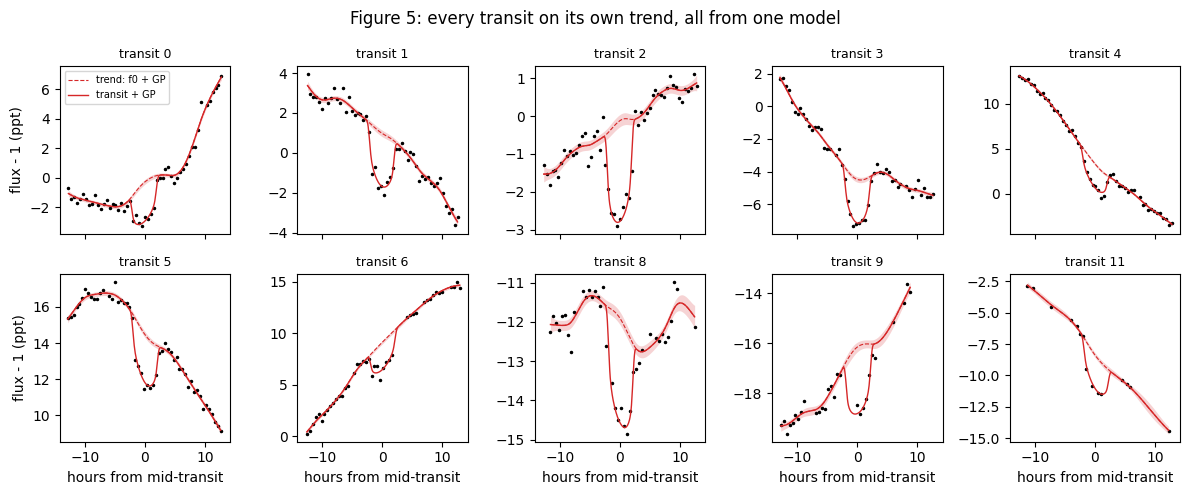

In [9]:
labels = list(result.labels)
rng = np.random.default_rng(2)
rows = result.samples[rng.choice(len(result.samples), 100, replace=False)]

def transit_of(row, times):
    """The transit of one row of samples, including the flux level f0."""
    c = dict(zip(labels, row))
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = c["t0"], c["per"], c["rp"], c["a"]
    p.inc = math.degrees(math.acos(c["b"] / c["a"]))
    sq = math.sqrt(c["q1"])
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", [2 * sq * c["q2"], sq * (1 - 2 * c["q2"])]
    tm = pizzetti.TransitModel(p, times, supersample_factor=K, exp_time=exposure, offsets="midpoint")
    return c["f0"] * tm.light_curve(p)

f0s = rows[:, labels.index("f0")]
fig, axs = plt.subplots(2, 5, figsize=(12, 5), sharex=True)
for ax, e in zip(axs.flat, epochs):
    m = ep == e
    fine = np.linspace(t[m][0], t[m][-1], 300)
    pred = [model.gp_predict(r, t=fine, return_var=True) for r in rows]
    gp_f = np.array([p[0] for p in pred])
    base = gp_f + f0s[:, None]          # the constant part of the GP is degenerate with f0: we plot their sum
    base_sd = np.sqrt(base.var(axis=0) + np.mean([p[1] for p in pred], axis=0))
    model_f = (np.array([transit_of(r, fine) for r in rows]) + gp_f).mean(axis=0)
    hours = 24 * (fine - e * P)
    ax.plot(24 * (t[m] - e * P), 1e3 * (y[m] - 1), "k.", ms=3)
    ax.fill_between(hours, 1e3 * (base.mean(axis=0) - base_sd - 1), 1e3 * (base.mean(axis=0) + base_sd - 1),
                    color="C3", alpha=0.2, lw=0)
    ax.plot(hours, 1e3 * (base.mean(axis=0) - 1), "C3--", lw=0.8, label="trend: f0 + GP")
    ax.plot(hours, 1e3 * (model_f - 1), "C3", lw=1, label="transit + GP")
    ax.set_title(f"transit {e}", fontsize=9)
for ax in axs[1]:
    ax.set_xlabel("hours from mid-transit")
for ax in axs[:, 0]:
    ax.set_ylabel("flux - 1 (ppt)")
axs[0, 0].legend(loc="best", fontsize=7)
fig.suptitle("Figure 5: every transit on its own trend, all from one model")
fig.tight_layout()

The trend runs steeply through several transits, and on some it turns over. The GP follows it in every window
with the same two parameters, and the band shows how well the trend under each transit is known: that
uncertainty is part of the posterior of the transit parameters. The corner plot shows that posterior; every point
of it has a physically possible limb-darkening profile:

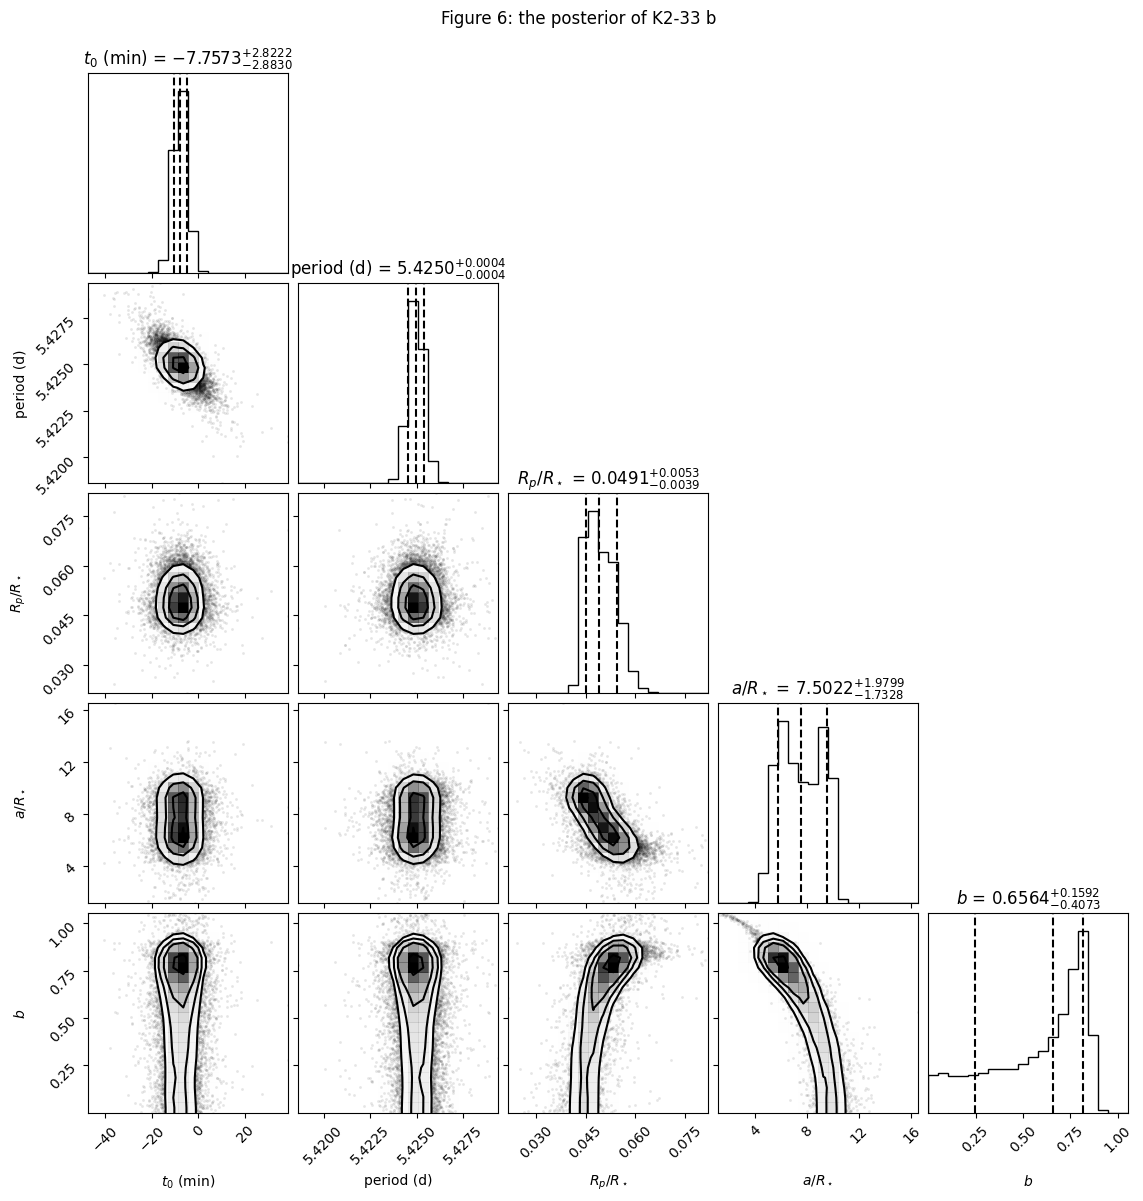

In [10]:
cols = ["t0", "per", "rp", "a", "b"]
X = np.column_stack([result.weighted_samples[:, labels.index(c)] for c in cols])
X[:, 0] *= 24 * 60                                         # t0 in minutes after the TLS epoch
fig = corner.corner(X, weights=result.weights, labels=[r"$t_0$ (min)", "period (d)", r"$R_p/R_\star$", r"$a/R_\star$", r"$b$"],
                    show_titles=True, title_fmt=".4f", quantiles=[0.16, 0.5, 0.84], smooth=1.0)
fig.suptitle("Figure 6: the posterior of K2-33 b", y=1.02);

## Step 6: physical quantities

The posterior draws turn into physical quantities. With the star's radius, Rp/R★ gives the planet's radius; we
draw the stellar radius from its uncertainty in David et al. (2016), 1.05 ± 0.07 R☉, so that it enters the error
bar. And a/R★ with the period gives the star's density (Kepler's third law), independent of the star's mass and
radius.

planet radius: 5.6 +0.7 -0.6 Earth radii
period: 5.42497 +0.00041 -0.00042 d
stellar density: 0.27 +0.28 -0.15 g/cm^3 (from M and R: 0.68, at the 98th percentile of the posterior)


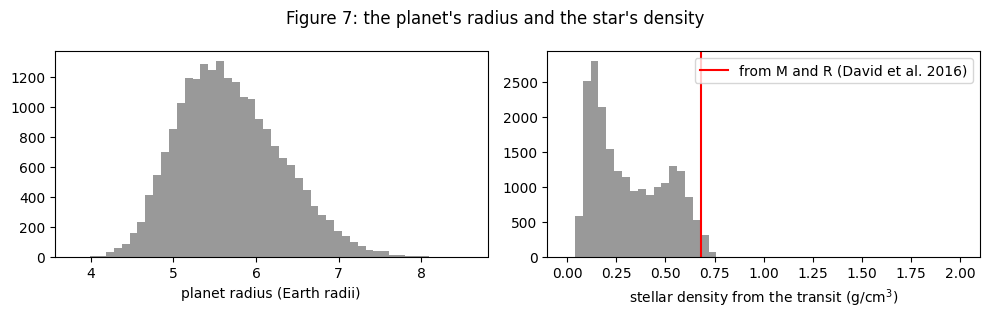

In [11]:
s = dict(zip(labels, result.samples.T))
rng = np.random.default_rng(3)
R_draw = rng.normal(R_star, 0.07, len(s["rp"]))
radius_planet = s["rp"] * R_draw * 109.08                  # Earth radii
G = 6.674e-8                                               # cgs
rho_star = 3 * np.pi * s["a"] ** 3 / (G * (s["per"] * 86400) ** 2)  # g/cm^3
rho_literature = M_star * 1.989e33 / (4 / 3 * np.pi * (R_star * 6.957e10) ** 3)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(radius_planet, bins=50, color="0.6")
ax[0].set_xlabel("planet radius (Earth radii)")
ax[1].hist(rho_star, bins=np.linspace(0, 2, 51), color="0.6")
ax[1].axvline(rho_literature, color="r", label="from M and R (David et al. 2016)")
ax[1].set_xlabel("stellar density from the transit (g/cm$^3$)"); ax[1].legend()
fig.suptitle("Figure 7: the planet's radius and the star's density")
fig.tight_layout()
q = lambda x: np.percentile(x, [16, 50, 84])
r, rho, per_q = q(radius_planet), q(rho_star), q(s["per"])
print(f"planet radius: {r[1]:.1f} +{r[2] - r[1]:.1f} -{r[1] - r[0]:.1f} Earth radii")
print(f"period: {per_q[1]:.5f} +{per_q[2] - per_q[1]:.5f} -{per_q[1] - per_q[0]:.5f} d")
print(f"stellar density: {rho[1]:.2f} +{rho[2] - rho[1]:.2f} -{rho[1] - rho[0]:.2f} g/cm^3 (from M and R: {rho_literature:.2f}, "
      f"at the {100 * np.mean(rho_star < rho_literature):.0f}th percentile of the posterior)")

K2-33 b is a planet of about 5.6 Earth radii on a 5.4-day orbit; the period agrees with the published one, and the
radius with the 5.0 ± 0.3 Earth radii of [David et al. (2016)](https://doi.org/10.1038/nature18293) within the
error bars. The density from the transit is broad and prefers low values: with a 30-minute cadence, a/R★ and b
are degenerate (pizzetti's tutorial
[why b is hard](https://github.com/hippke/pizzetti/blob/main/examples/13_why_b_is_hard.ipynb)), and a grazing
geometry with a small a/R★ fits the transits as well as a central one. The density from mass and radius lies at
the 98th percentile of this posterior: either the transit is near-grazing, or the orbit is eccentric. A fit with
eccentricity and a prior on the stellar density takes it from here (pizzetti's tutorial
[eccentricity from a stellar density](https://github.com/hippke/pizzetti/blob/main/examples/20_eccentricity_from_a_stellar_density.ipynb)).

## What you learned

- **lightkurve** downloads the light curve; bad cadences go before anything else, because every search takes the
  deepest dips seriously.
- **TLS 2.0 + GP** finds the planet in the light curve as it is: the star is a GP, fitted once and integrated out
  inside the search, so there is no detrending filter, window or mask to choose. It also gives the GP's trend.
- **pizzetti** fits the transit and a GP together, in time order, by importance sampling in seconds, with the limb
  darkening integrated out; the uncertainty of the trend under each transit is part of the posterior.

**More:** the classical route, [the Grand Tour with wotan](12%20The%20Grand%20Tour%20-%20from%20download%20to%20posterior.ipynb); TLS's tutorial
[TLS with a GP baseline](https://github.com/hippke/tls/blob/master/tutorials/13%20TLS%20with%20a%20GP%20baseline%20-%20a%20spotted%20star%20with%20a%20planet.ipynb)
and its documentation of the [GP search](https://github.com/hippke/tls/blob/master/docs/GP-search.md); pizzetti's
[fitting with a Gaussian process](https://github.com/hippke/pizzetti/blob/main/examples/18_fitting_with_a_gaussian_process.ipynb),
which compares the GP with three filters on the same star, and when to be careful with a GP.